# Análise de Dispensação de Medicamentos
## Sprint 2 - PyAnalytics

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## 1. Carregamento e Preparação dos Dados



In [2]:
df = pd.read_csv("../../data/processed/dispensacao_analitico.csv")
print(f"Total de registros: {len(df)}")
print(f"Período: {df['data'].min()} até {df['data'].max()}")
df.head()

Total de registros: 220815
Período: 2025-08-01 até 2026-08-04


,competencia_inicial,competencia_final,ups_nome,ups_codigo,bairro_nome,bairro_codigo,centro_custo_nome,centro_custo_codigo,material_nome,material_nome_base,material_descricao_complementar,material_tipo,classe_terapeutica,tipo_tratamento,material_codigo,data,saida,usuario,fabricante_codigo,fabricante_nome,lote,numero_receita,validade,quantidade,custo_medio
0,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,CARBONATO DE LITIO - 300MG - COMPRIMIDO,CARBONATO DE LITIO,300MG,COMPRIMIDO,ANTIDEPRESSIVOS,Saude mental e neurologia,190.1,2025-09-02,776110,X,41.0,CRISTALIA,23100497,NaN,2025-10-02,90,0.19
1,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,CLORPROMAZINA - 25MG - COMPRIMIDO,CLORPROMAZINA,25MG,COMPRIMIDO,NEUROLEPTICOS,Saude mental e neurologia,219.1,2025-09-18,781751,X,41.0,CRISTALIA,50023423,NaN,2027-01-30,240,0.28
2,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,IMIPRAMINA - 25MG - COMPRIMIDO,IMIPRAMINA,25MG,COMPRIMIDO,ANTIDEPRESSIVOS,Saude mental e neurologia,237.1,2025-09-09,778225,X,41.0,CRISTALIA,50025335,NaN,2027-01-31,180,0.44
3,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,MIRTAZAPINA - 45MG - COMPRIMIDO,MIRTAZAPINA,45MG,COMPRIMIDO,ANTIDEPRESSIVOS,Saude mental e neurologia,238.1,2025-09-18,781751,X,2.0,PRATI DONADUZZI,25D360,NaN,2027-03-13,60,0.86
4,202508,202509.0,FARMACIA BASICA MUNICIPAL,101,AEROPORTO,67.0,CAPS,13.0,VENLAFAXINA - 75MG - COMPRIMIDO,VENLAFAXINA,75MG,COMPRIMIDO,ANTIDEPRESSIVOS,Saude mental e neurologia,247.1,2025-09-02,776110,X,40.0,AUROBINDO,VWB25001,NaN,2027-12-31,120,0.36


In [3]:
print(df.columns.tolist())
df.info()

['competencia_inicial', 'competencia_final', 'ups_nome', 'ups_codigo', 'bairro_nome', 'bairro_codigo', 'centro_custo_nome', 'centro_custo_codigo', 'material_nome', 'material_nome_base', 'material_descricao_complementar', 'material_tipo', 'classe_terapeutica', 'tipo_tratamento', 'material_codigo', 'data', 'saida', 'usuario', 'fabricante_codigo', 'fabricante_nome', 'lote', 'numero_receita', 'validade', 'quantidade', 'custo_medio']
<class 'pandas.DataFrame'>
RangeIndex: 220815 entries, 0 to 220814
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   competencia_inicial              220815 non-null  int64  
 1   competencia_final                219080 non-null  float64
 2   ups_nome                         220815 non-null  str    
 3   ups_codigo                       220815 non-null  int64  
 4   bairro_nome                      220815 non-null  str    
 5   bairro_codigo        

In [4]:
# Valores nulos por coluna
df.isnull().sum()

competencia_inicial                     0
competencia_final                    1735
ups_nome                                0
ups_codigo                              0
bairro_nome                             0
bairro_codigo                          23
centro_custo_nome                       0
centro_custo_codigo                199272
material_nome                           0
material_nome_base                      0
material_descricao_complementar         0
material_tipo                           0
classe_terapeutica                   8473
tipo_tratamento                      1560
material_codigo                         0
data                                    0
saida                                   0
usuario                                 0
fabricante_codigo                      66
fabricante_nome                        66
lote                                   66
numero_receita                     213616
validade                               66
quantidade                        

In [5]:
# Valores únicos nas colunas categóricas principais
print(f"UPS (unidades): {df['ups_nome'].nunique()}")
print(f"Bairros: {df['bairro_nome'].nunique()}")
print(f"Medicamentos (nome base): {df['material_nome_base'].nunique()}")
print(f"Tipos de apresentação: {df['material_tipo'].nunique()}")
print(f"Classes terapêuticas: {df['classe_terapeutica'].nunique()}")
print(f"Tipos de tratamento: {df['tipo_tratamento'].nunique()}")

UPS (unidades): 1
Bairros: 157
Medicamentos (nome base): 115
Tipos de apresentação: 8
Classes terapêuticas: 56
Tipos de tratamento: 12


### Observações sobre os Dados



Das colunas com valores nulos, apenas `classe_terapeutica` e `tipo_tratamento` são utilizadas nesta análise (3,8% de nulos, 8.473 registros, mesmas linhas nas duas colunas).  Optou-se por manter esses nulos sem tratamento, pois removê-los descartaria saídas reais dos rankings gerais.


## 2. Quais Medicamentos Mais se Destacam?

### a. Por Número de Saídas (frequência de movimentações)

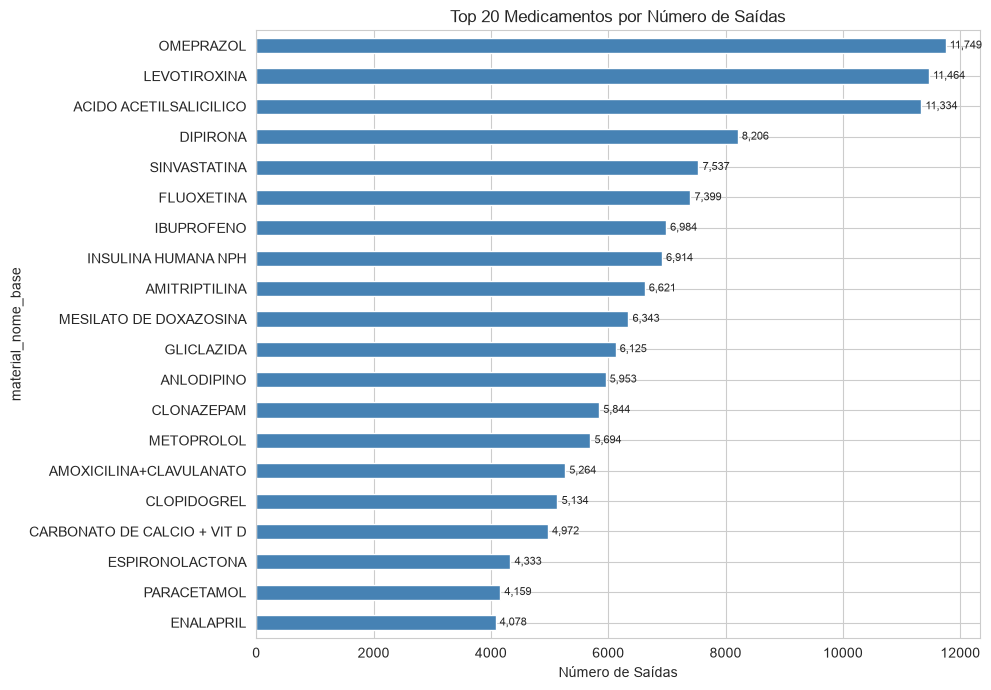

In [6]:
# Top 20 por número de saídas (linhas na base)
top_saidas = df["material_nome_base"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(10, 7))
top_saidas.plot(kind="barh", ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set_title("Top 20 Medicamentos por Número de Saídas")
ax.set_xlabel("Número de Saídas")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width()):,}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

O omeprazol lidera o ranking de saídas (11.749), seguido de perto pela levotiroxina (11.464) e ácido acetilsalicílico (11.334), os três com volumes muito próximos, sugerindo demanda igualmente intensa. A predominância de protetores gástricos, hormônios tireoidianos, antiagregantes e estatinas confirma que a dispensação em Araranguá é dominada por medicamentos de uso contínuo para doenças crônicas, o que é esperado num sistema público de atenção básica.

### b. Por Quantidade Total Dispensada

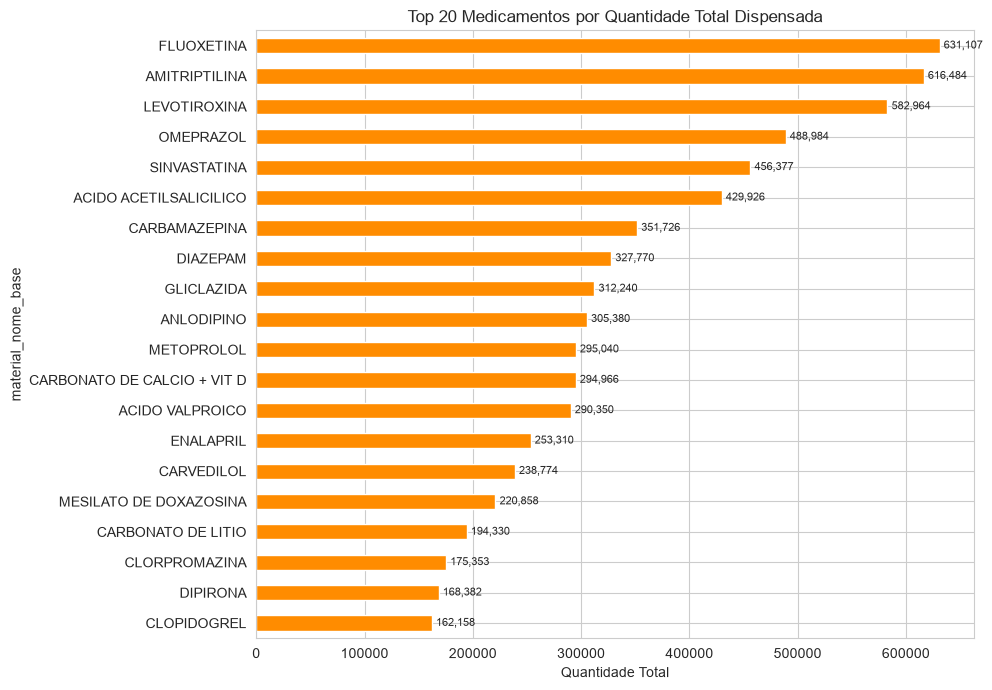

In [7]:
# Top 20 por quantidade total dispensada
top_quantidade = df.groupby("material_nome_base")["quantidade"].sum().sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 7))
top_quantidade.plot(kind="barh", ax=ax, color="darkorange")
ax.invert_yaxis()
ax.set_title("Top 20 Medicamentos por Quantidade Total Dispensada")
ax.set_xlabel("Quantidade Total")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width()):,}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

O ranking por quantidade total inverte a ordem: fluoxetina (631.107 unidades) e amitriptilina (616.484) saltam para o topo, enquanto omeprazol cai para 4º. Isso revela que medicamentos de saúde mental, embora não sejam os mais frequentemente retirados, saem em volumes muito maiores por saída, provavelmente por esquemas de doses mais altas ou dispensação para períodos mais longos. 

### c. Comparação entre os dois rankings

In [8]:
# Compara posição no ranking de saídas vs quantidade
rank_saidas = df["material_nome_base"].value_counts().reset_index()
rank_saidas.columns = ["material", "saidas"]
rank_saidas["rank_saidas"] = range(1, len(rank_saidas) + 1)

rank_qtd = df.groupby("material_nome_base")["quantidade"].sum().reset_index()
rank_qtd.columns = ["material", "quantidade"]
rank_qtd = rank_qtd.sort_values("quantidade", ascending=False).reset_index(drop=True)
rank_qtd["rank_quantidade"] = range(1, len(rank_qtd) + 1)

comparacao = rank_saidas.merge(rank_qtd, on="material").head(20)
print("Top 20 por saídas — com posição no ranking de quantidade:")
print(comparacao[["material", "saidas", "rank_saidas", "quantidade", "rank_quantidade"]].to_string(index=False))

Top 20 por saídas — com posição no ranking de quantidade:
                   material  saidas  rank_saidas  quantidade  rank_quantidade
                  OMEPRAZOL   11749            1      488984                4
               LEVOTIROXINA   11464            2      582964                3
     ACIDO ACETILSALICILICO   11334            3      429926                6
                   DIPIRONA    8206            4      168382               19
               SINVASTATINA    7537            5      456377                5
                 FLUOXETINA    7399            6      631107                1
                 IBUPROFENO    6984            7      109945               27
        INSULINA HUMANA NPH    6914            8       27102               61
              AMITRIPTILINA    6621            9      616484                2
     MESILATO DE DOXAZOSINA    6343           10      220858               16
                 GLICLAZIDA    6125           11      312240                9
      

A comparação expõe diferenças expressivas: a insulina humana NPH, 8ª por saídas, cai para 61ª em quantidade, ou seja, é retirada com frequência altíssima, mas em pequenas quantidades por vez, o que reflete a dispensação fracionada típica de insulinas. No sentido oposto, fluoxetina (1ª em quantidade, 6ª em saídas) e amitriptilina (2ª em quantidade, 9ª em saídas) são dispensadas com menos frequência, mas em grandes volumes unitários. Dipirona e ibuprofeno também caem consideravelmente no ranking de quantidade, confirmando uso pontual com doses menores.

## 3. A Posição dos Medicamentos Muda Conforme o Período?

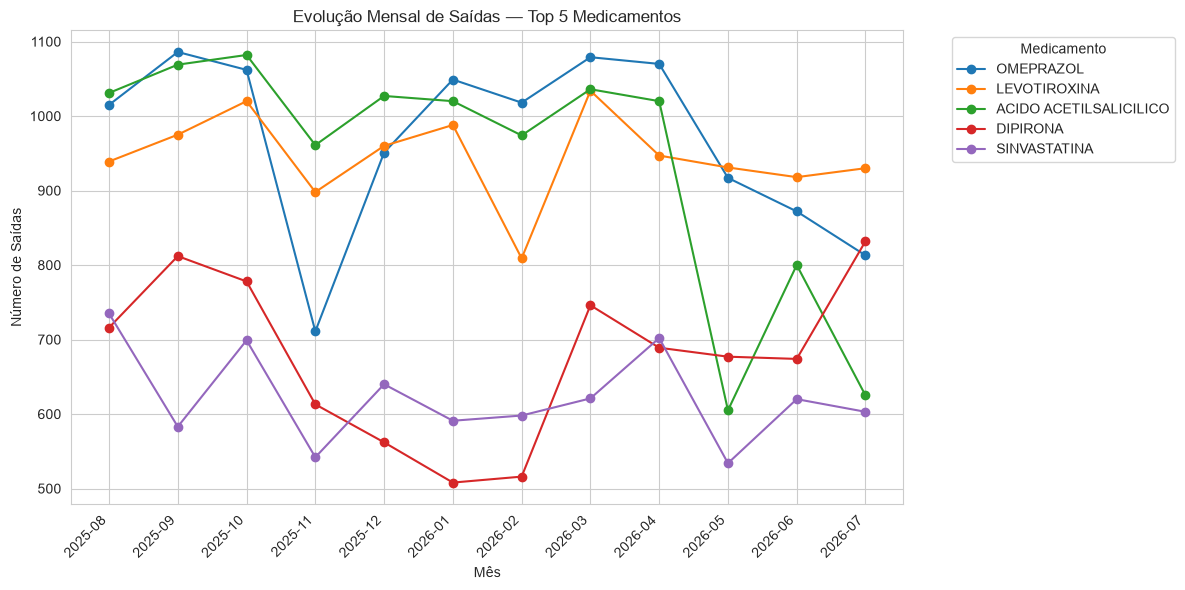

In [9]:
# Converte data
df["data"] = pd.to_datetime(df["data"], errors="coerce")
df["ano_mes"] = df["data"].dt.to_period("M")
df = df[df["ano_mes"].astype(str) != "2026-08"] #Remove o mês completo de agosto de 2026

# Top 5 medicamentos por saídas no geral
top5 = df["material_nome_base"].value_counts().head(5).index.tolist()

# Evolução mensal do número de saídas dos top 5
evolucao = (
    df[df["material_nome_base"].isin(top5)]
    .groupby(["ano_mes", "material_nome_base"])
    .size()
    .reset_index(name="saidas")
)
evolucao["ano_mes"] = evolucao["ano_mes"].astype(str)

fig, ax = plt.subplots(figsize=(12, 6))
for med in top5:
    dados = evolucao[evolucao["material_nome_base"] == med]
    ax.plot(dados["ano_mes"], dados["saidas"], marker="o", label=med)

ax.set_title("Evolução Mensal de Saídas — Top 5 Medicamentos")
ax.set_xlabel("Mês")
ax.set_ylabel("Número de Saídas")
ax.legend(title="Medicamento", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

O omeprazol apresentou crescimento consistente entre novembro e maio, recuperando-se da queda de novembro de 2025 que, conforme visto na análise temporal, coincidiu com redução real na quantidade dispensada, sugerindo desabastecimento temporário. A dipirona exibiu comportamento sazonal: alta entre março e agosto (outono/inverno) e queda entre outubro e fevereiro, o que é coerente com maior demanda por analgésicos e antitérmicos no período frio. Os demais medicamentos permaneceram relativamente estáveis ao longo do ano, com oscilações dentro de uma faixa regular (comportamento esperado para medicamentos de uso contínuo). Novembro e maio se destacam como meses de queda generalizada, o que pode indicar interrupções sazonais no abastecimento ou no funcionamento da unidade.

In [10]:
# Verifica quantidade total dispensada de omeprazol por mês
df[df["material_nome_base"].str.contains("OMEPRAZOL", case=False, na=False)].groupby("ano_mes")["quantidade"].sum()

ano_mes
2025-08    38266
2025-09    40692
2025-10    52514
2025-11    29600
2025-12    37114
2026-01    38832
2026-02    37628
2026-03    41120
2026-04    42910
2026-05    40304
2026-06    44538
2026-07    39470
Freq: M, Name: quantidade, dtype: int64

Em novembro de 2025, o omeprazol registrou queda expressiva tanto no número de saídas quanto na quantidade total dispensada (29.600 unidades, contra uma média de ~40.000 nos demais meses), sugerindo desabastecimento temporário. A recuperação gradual nos meses seguintes indica normalização do abastecimento. 

## 4. Apresentações e Dosagens em Destaque

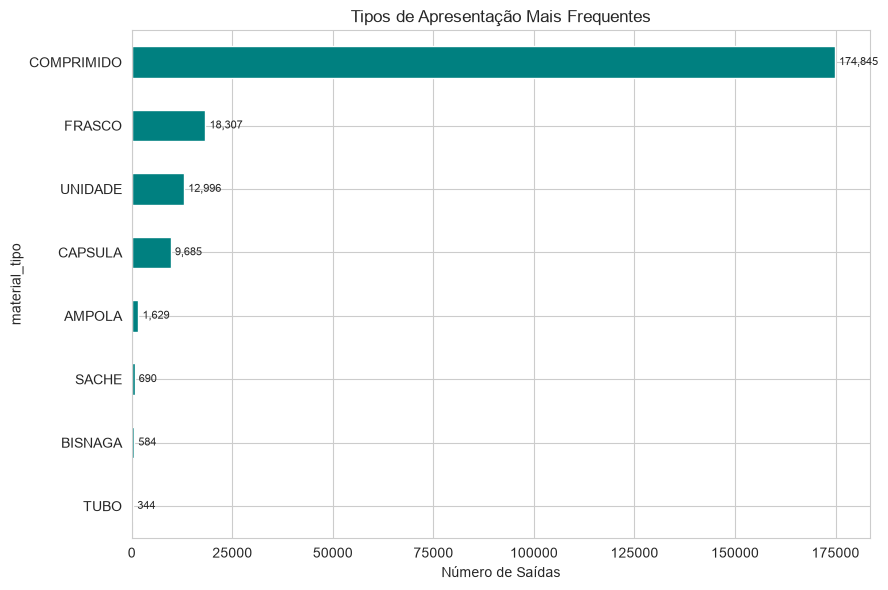

In [11]:
# Tipos de apresentação mais frequentes
tipo_freq = df["material_tipo"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9, 6))
tipo_freq.plot(kind="barh", ax=ax, color="teal")
ax.invert_yaxis()
ax.set_title("Tipos de Apresentação Mais Frequentes")
ax.set_xlabel("Número de Saídas")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width()):,}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

Comprimidos dominam disparadamente as dispensações, o que é esperado, dado que a maioria dos medicamentos crônicos de alta rotatividade (omeprazol, levotiroxina, sinvastatina, dipirona) é apresentada nessa forma. Frascos em segundo lugar refletem a presença de medicamentos líquidos e injetáveis, como insulinas e soluções. A baixa representatividade das demais apresentações (abaixo de 2.000 saídas) indica que a base é fortemente concentrada em formas sólidas orais, mais simples de dispensar e armazenar.

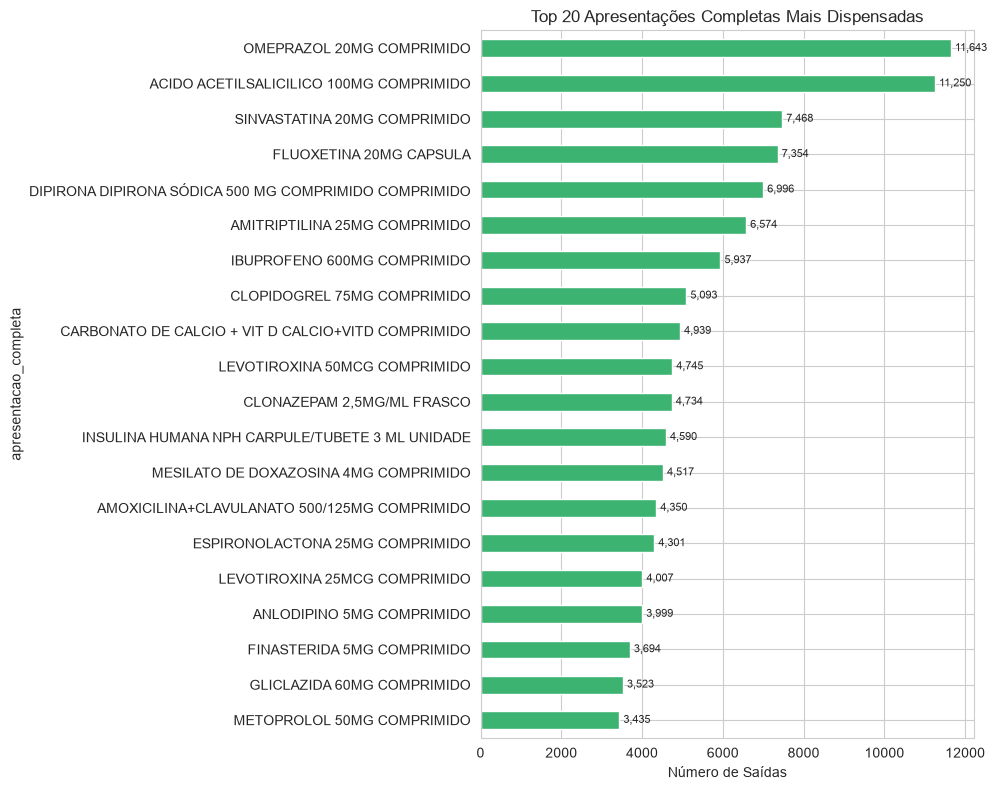

In [12]:
# Top apresentações completas (nome base + complementar + tipo)
df["apresentacao_completa"] = (
    df["material_nome_base"].fillna("") + " " +
    df["material_descricao_complementar"].fillna("") + " " +
    df["material_tipo"].fillna("")
).str.strip()

top_apresentacoes = df["apresentacao_completa"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(10, 8))
top_apresentacoes.plot(kind="barh", ax=ax, color="mediumseagreen")
ax.invert_yaxis()
ax.set_title("Top 20 Apresentações Completas Mais Dispensadas")
ax.set_xlabel("Número de Saídas")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width()):,}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

As apresentações mais dispensadas reforçam o perfil crônico da base: omeprazol 20mg, acetilsalicílico 100mg e sinvastatina 20mg são dosagens padrão de manutenção para gastrite/refluxo, prevenção cardiovascular e controle de colesterol, respectivamente. A presença de fluoxetina 20mg cápsula e amitriptilina 25mg comprimido no top reforça o peso da saúde mental já observado no ranking de quantidade. Ibuprofeno 600mg (dosagem mais alta, indicada para dor mais intensa) chama atenção por aparecer entre as mais dispensadas, sugerindo uso além do básico.

## 5. Análise por Classe Terapêutica e Tipo de Tratamento

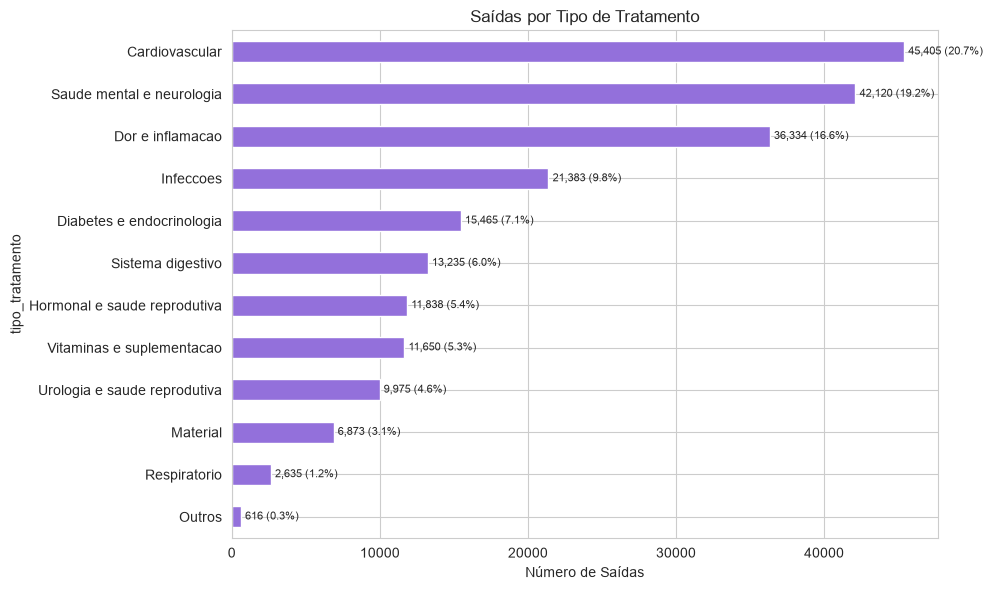

In [13]:
# Distribuição por tipo de tratamento
tipo_trat = df["tipo_tratamento"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
tipo_trat.plot(kind="barh", ax=ax, color="mediumpurple")
ax.invert_yaxis()
ax.set_title("Saídas por Tipo de Tratamento")
ax.set_xlabel("Número de Saídas")

for bar in ax.patches:
    pct = bar.get_width() / len(df) * 100
    ax.annotate(f"{int(bar.get_width()):,} ({pct:.1f}%)",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

A categoria mais representativa é cardiovascular (20%), reunindo medicamentos de controle de pressão arterial e colesterol — condições crônicas de alta prevalência na população adulta. Saúde mental e neurologia (19%) aparece logo em seguida, evidenciando o peso significativo dos tratamentos psiquiátricos e neurológicos na dispensação do município.

In [14]:
# Top 5 medicamentos por tipo de tratamento
tipos = df["tipo_tratamento"].value_counts().head(5).index.tolist()

for tipo in tipos:
    top_med = (
        df[df["tipo_tratamento"] == tipo]["material_nome_base"]
        .value_counts()
        .head(5)
    )
    print(f"\n {tipo}")
    print(top_med.to_string())


 Cardiovascular
material_nome_base
SINVASTATINA       7468
ANLODIPINO         5911
METOPROLOL         5644
CLOPIDOGREL        5093
ESPIRONOLACTONA    4301

 Saude mental e neurologia
material_nome_base
FLUOXETINA       7354
AMITRIPTILINA    6574
CLONAZEPAM       5813
DIAZEPAM         3045
CARBAMAZEPINA    2271

 Dor e inflamacao
material_nome_base
ACIDO ACETILSALICILICO    11250
DIPIRONA                   8123
IBUPROFENO                 6916
PARACETAMOL                4125
PREDNISONA                 3768

 Infeccoes
material_nome_base
AMOXICILINA+CLAVULANATO    5209
AMOXICILINA                3368
AZITROMICINA               3132
CEFALEXINA                 1987
CIPROFLOXACINO             1168

 Diabetes e endocrinologia
material_nome_base
INSULINA HUMANA NPH        6864
GLICLAZIDA                 6070
INSULINA HUMANA REGULAR    2531


## 6. Análise por Unidade de Dispensação (UPS) e Bairro

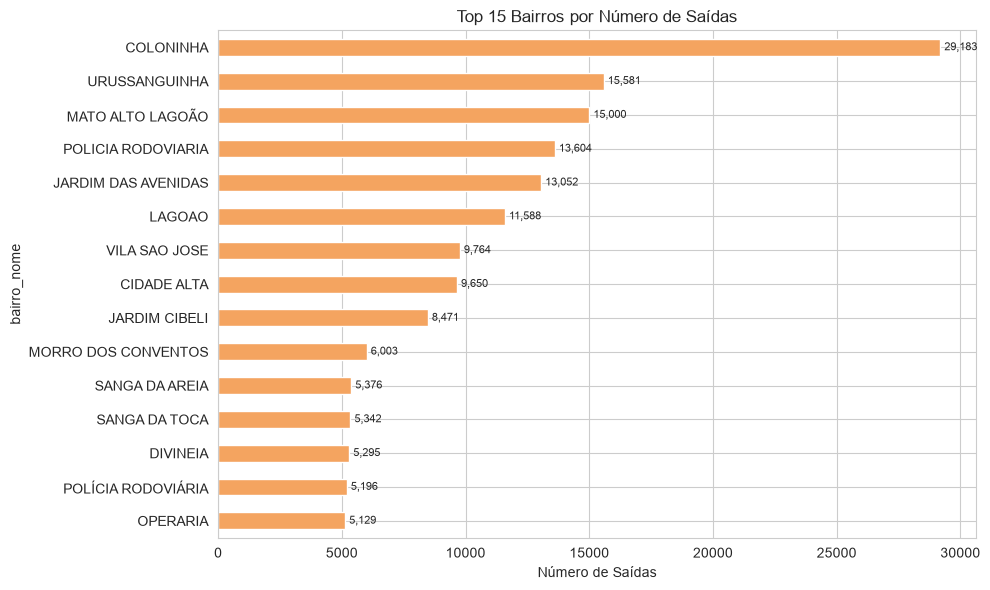

In [15]:
# Top bairros por volume de saídas
top_bairros = df["bairro_nome"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
top_bairros.plot(kind="barh", ax=ax, color="sandybrown")
ax.invert_yaxis()
ax.set_title("Top 15 Bairros por Número de Saídas")
ax.set_xlabel("Número de Saídas")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width()):,}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

Os bairros com maior volume de saídas: Coloninha, Urussanguinha, Mato Alto, Lagoão. Provavelmente concentram maior populaçao ou maior demanda por medicamentos conforme perfil populacional desses bairros.

## 7. Top 5 por Bairro — O Omeprazol Domina em Todos?

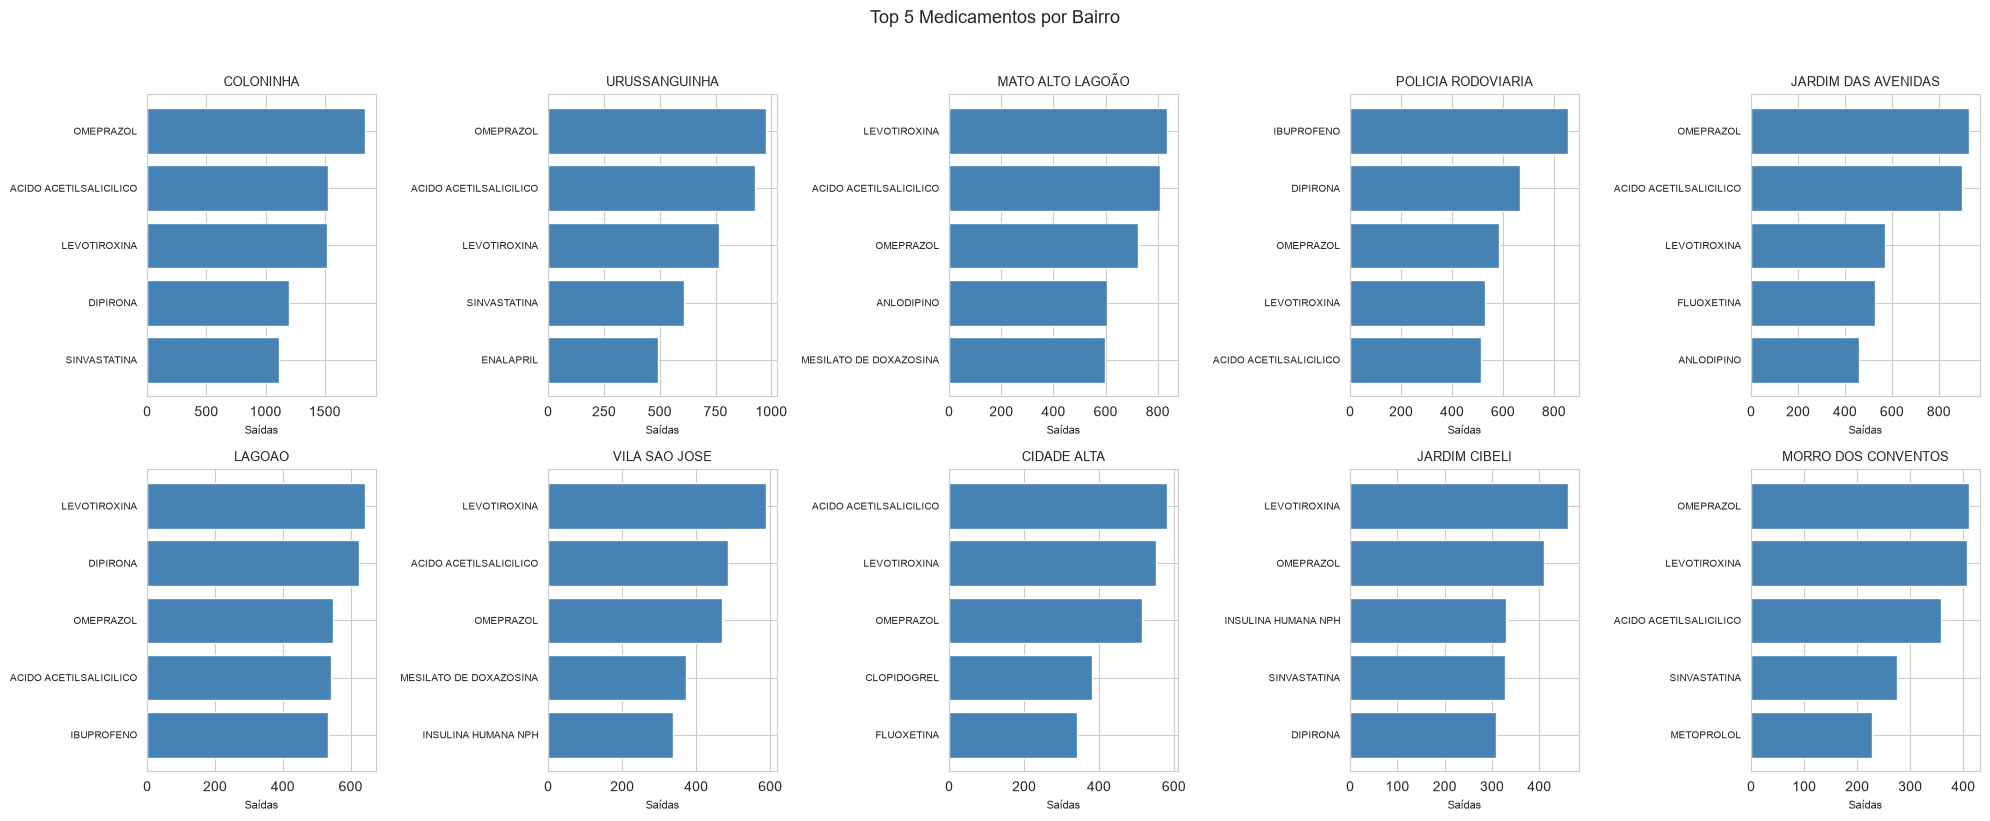

In [16]:
# Top 5 medicamentos por bairro
top5_geral = df["material_nome_base"].value_counts().head(5).index.tolist()
bairros_top = df["bairro_nome"].value_counts().head(10).index.tolist()

df_bairros = df[df["bairro_nome"].isin(bairros_top)]

pivot_bairro = (
    df_bairros.groupby(["bairro_nome", "material_nome_base"])
    .size()
    .reset_index(name="saidas")
)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=False)
axes = axes.flatten()

for i, bairro in enumerate(bairros_top):
    dados = (
        pivot_bairro[pivot_bairro["bairro_nome"] == bairro]
        .sort_values("saidas", ascending=False)
        .head(5)
    )
    ax = axes[i]
    ax.barh(dados["material_nome_base"], dados["saidas"], color="steelblue")
    ax.invert_yaxis()
    ax.set_title(bairro, fontsize=9)
    ax.set_xlabel("Saídas", fontsize=8)
    ax.tick_params(axis="y", labelsize=7)

plt.suptitle("Top 5 Medicamentos por Bairro", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

A variação entre bairros é um dado relevante: Mato Alto e Lagoão têm a levotiroxina como medicamento mais dispensado, deslocando o omeprazol do topo, o que pode indicar maior prevalência de hipotireoidismo nessas populações, ou que esses bairros atendem um perfil etário mais envelhecido (hipotireoidismo é mais comum em mulheres acima de 40 anos). A liderança do ibuprofeno na Polícia Rodoviária é incomum para uma atenção básica típica. Pode atender uma população com maior demanda por analgésicos, como trabalhadores ou vítimas de acidentes de trânsito da BR-101, que corta o município.

## 8. Média de Quantidade por Saída por Medicamento

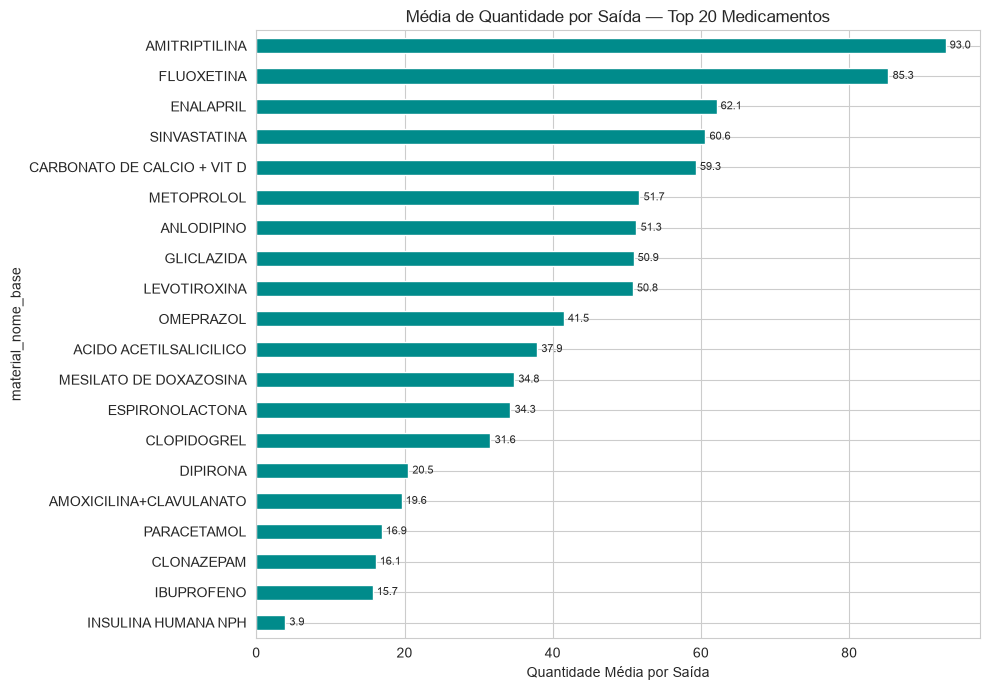

In [17]:
# Média de quantidade dispensada por saída — top 20 medicamentos por saídas
top20_med = df["material_nome_base"].value_counts().head(20).index.tolist()

media_qtd = (
    df[df["material_nome_base"].isin(top20_med)]
    .groupby("material_nome_base")["quantidade"]
    .mean()
    .sort_values(ascending=False)
    .round(1)
)

fig, ax = plt.subplots(figsize=(10, 7))
media_qtd.plot(kind="barh", ax=ax, color="darkcyan")
ax.invert_yaxis()
ax.set_title("Média de Quantidade por Saída — Top 20 Medicamentos")
ax.set_xlabel("Quantidade Média por Saída")

for bar in ax.patches:
    ax.annotate(f"{bar.get_width():.1f}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

Amitriptilina e fluoxetina lideram a média de quantidade por saída, o que explica sua posição no topo do ranking de quantidade total apesar de não serem os mais frequentes em saídas. Enalapril, sinvastatina e carbonato de cálcio também apresentam médias altas, compatíveis com dispensação em volumes maiores por saída, padrão esperado para medicamentos de uso contínuo cujas saídas tendem a cobrir períodos mais longos. No extremo oposto, dipirona, paracetamol, ibuprofeno e insulina humana registram as menores médias por saída. A insulina se destaca nesse grupo, pois sua dispensação fracionada em pequenas quantidades é uma prática de controle de estoque e conservação, dado que o produto exige armazenamento refrigerado.

## 9. Sazonalidade por Classe Terapêutica

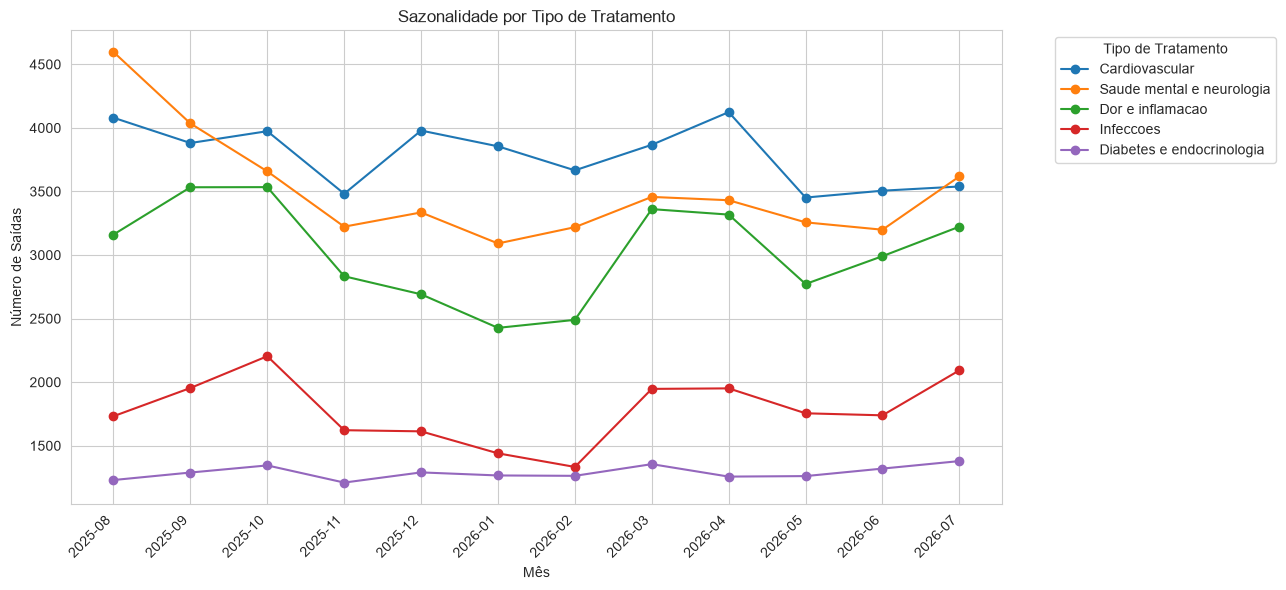

In [18]:
# Filtra agosto de 2026
df_sazonal = df[df["ano_mes"].astype(str) != "2026-08"].copy()

# Classes terapêuticas de interesse para sazonalidade
classes_interesse = [
    "Antibióticos e antimicrobianos",
    "Analgésicos e antitérmicos",
    "Sistema respiratório",
    "Saúde mental e neurologia",
    "Doenças cardiovasculares",
]

# Usa as classes que realmente existem na base
classes_existentes = [c for c in classes_interesse if c in df_sazonal["tipo_tratamento"].values]

if not classes_existentes:
    # Se os nomes não baterem exatamente, usa os top 5 tipos de tratamento
    classes_existentes = df_sazonal["tipo_tratamento"].value_counts().head(5).index.tolist()

evolucao_classe = (
    df_sazonal[df_sazonal["tipo_tratamento"].isin(classes_existentes)]
    .groupby(["ano_mes", "tipo_tratamento"])
    .size()
    .reset_index(name="saidas")
)
evolucao_classe["ano_mes"] = evolucao_classe["ano_mes"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))
for classe in classes_existentes:
    dados = evolucao_classe[evolucao_classe["tipo_tratamento"] == classe]
    ax.plot(dados["ano_mes"], dados["saidas"], marker="o", label=classe)

ax.set_title("Sazonalidade por Tipo de Tratamento")
ax.set_xlabel("Mês")
ax.set_ylabel("Número de Saídas")
ax.legend(title="Tipo de Tratamento", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

A estabilidade de diabetes e cardiovascular ao longo de todo o ano confirma o caráter crônico dessas condições. O abastecimento dessas categorias pode ser planejado de forma linear, sem necessidade de ajuste sazonal. Saúde mental apresentou queda entre agosto e outubro, o que pode estar relacionado ao mesmo evento de desabastecimento observado no omeprazol em novembro. Dor e inflamação teve dois picos distintos (agosto–novembro e fevereiro–maio), sugerindo sazonalidade influenciada tanto pelo inverno quanto por outros fatores ainda não identificados.